In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nikhil7280/student-performance-multiple-linear-regression")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'student-performance-multiple-linear-regression' dataset.
Path to dataset files: /kaggle/input/student-performance-multiple-linear-regression


In [5]:
import os
import pandas as pd
import kagglehub

LOCAL_FILE = "student_performance.csv"

if os.path.exists(LOCAL_FILE):
    df = pd.read_csv(LOCAL_FILE)
else:
    path = kagglehub.dataset_download("nikhil7280/student-performance-multiple-linear-regression")
    print("Path to dataset files:", path)

    csv_files = [f for f in os.listdir(path) if f.lower().endswith(".csv")]
    print("CSV files:", csv_files)

    df = pd.read_csv(os.path.join(path, csv_files[0]))
    df.to_csv(LOCAL_FILE, index=False)   # cache locally so next run skips the download

Using Colab cache for faster access to the 'student-performance-multiple-linear-regression' dataset.
Path to dataset files: /kaggle/input/student-performance-multiple-linear-regression
CSV files: ['Student_Performance.csv']


In [6]:
print(df.shape)
df.head()

(10000, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [7]:

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# df is loaded using the kagglehub code from before
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [8]:
df.info()
display(df.describe().T)
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


,count,mean,std,min,25%,50%,75%,max
Hours Studied,10000.0,4.9929,2.589309,1.0,3.0,5.0,7.0,9.0
Previous Scores,10000.0,69.4457,17.343152,40.0,54.0,69.0,85.0,99.0
Sleep Hours,10000.0,6.5306,1.695863,4.0,5.0,7.0,8.0,9.0
Sample Question Papers Practiced,10000.0,4.5833,2.867348,0.0,2.0,5.0,7.0,9.0
Performance Index,10000.0,55.2248,19.212558,10.0,40.0,55.0,71.0,100.0


(10000, 6)


In [9]:
# Missing values (also check for placeholders like "?", as in your earlier dataset)
print("Missing:\n", df.isna().sum())
print("Placeholders:\n", (df == "?").sum().sum())

# Duplicates
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Tidy column names (easier to type, fewer typos)
df.columns = (df.columns.str.strip()
                        .str.lower()
                        .str.replace(" ", "_"))
print(df.columns.tolist())

Missing:
 Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64
Placeholders:
 0
Duplicate rows: 127
['hours_studied', 'previous_scores', 'extracurricular_activities', 'sleep_hours', 'sample_question_papers_practiced', 'performance_index']


In [10]:
df["extracurricular_activities"] = df["extracurricular_activities"].map({"Yes": 1, "No": 0})
df["extracurricular_activities"].value_counts()

,count
extracurricular_activities,
0,4986
1,4887


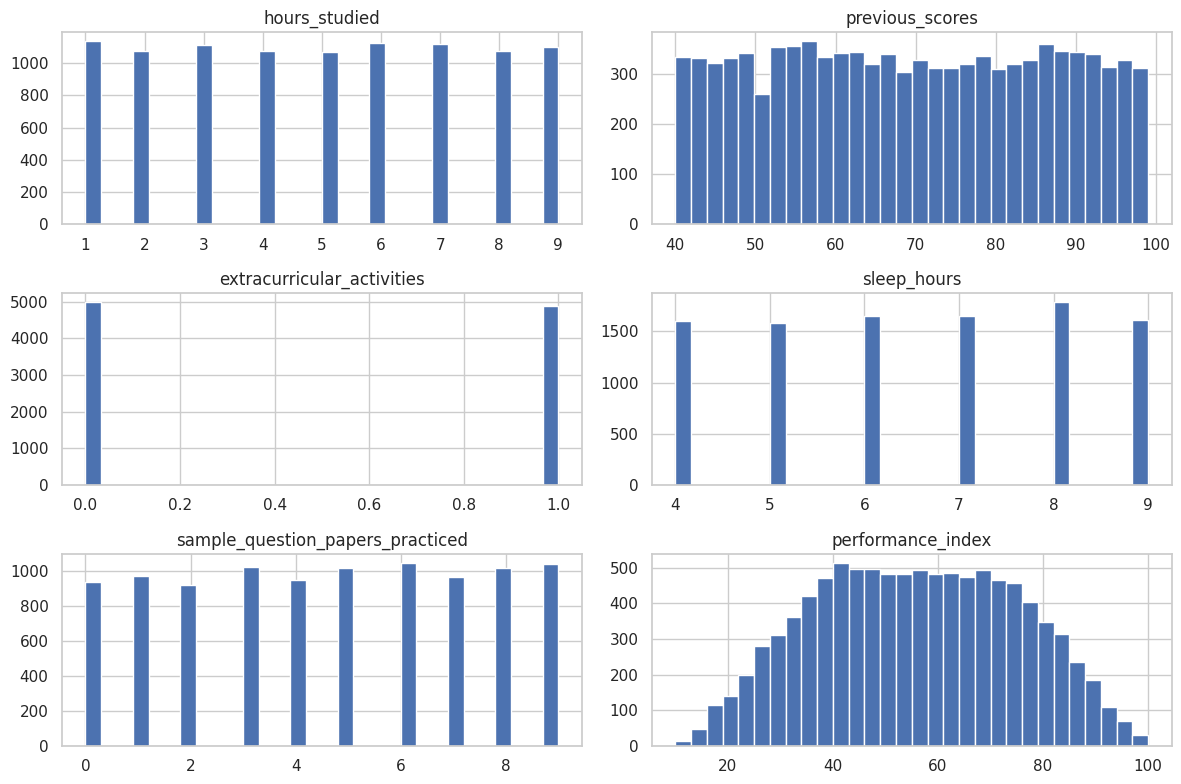

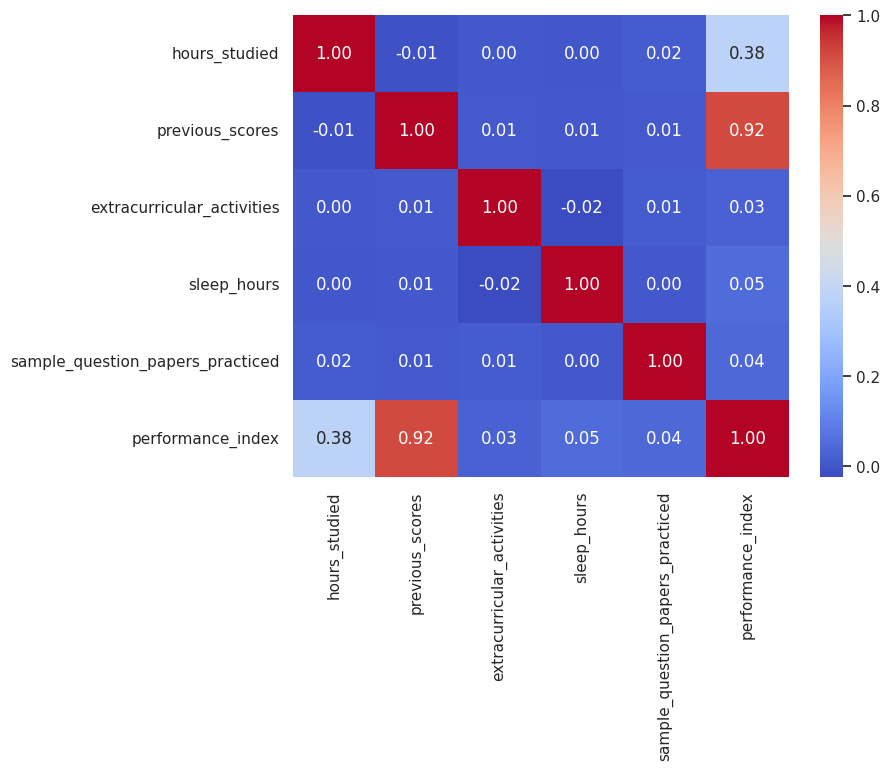

performance_index                   1.000000
previous_scores                     0.915135
hours_studied                       0.375332
sleep_hours                         0.050352
sample_question_papers_practiced    0.043436
extracurricular_activities          0.026075
Name: performance_index, dtype: float64


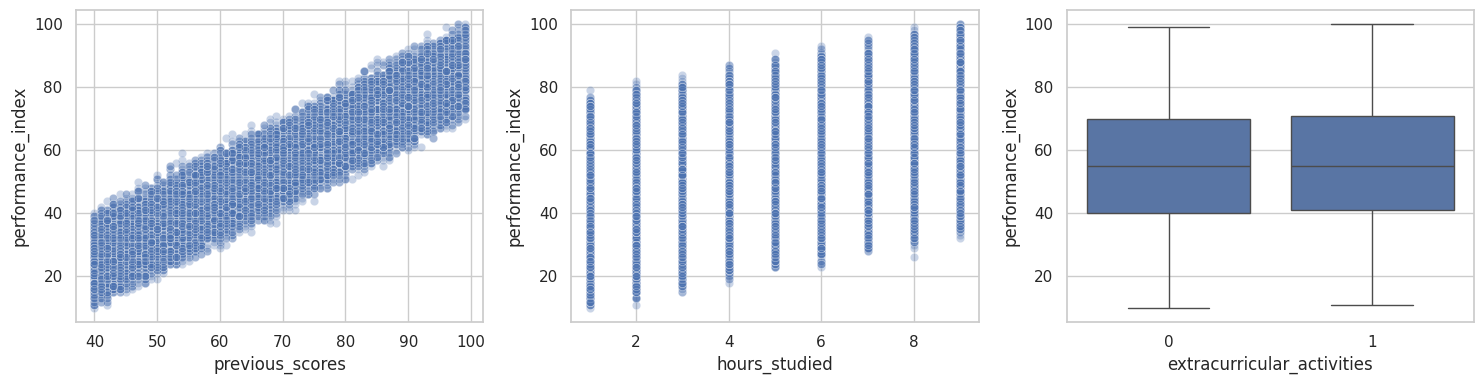

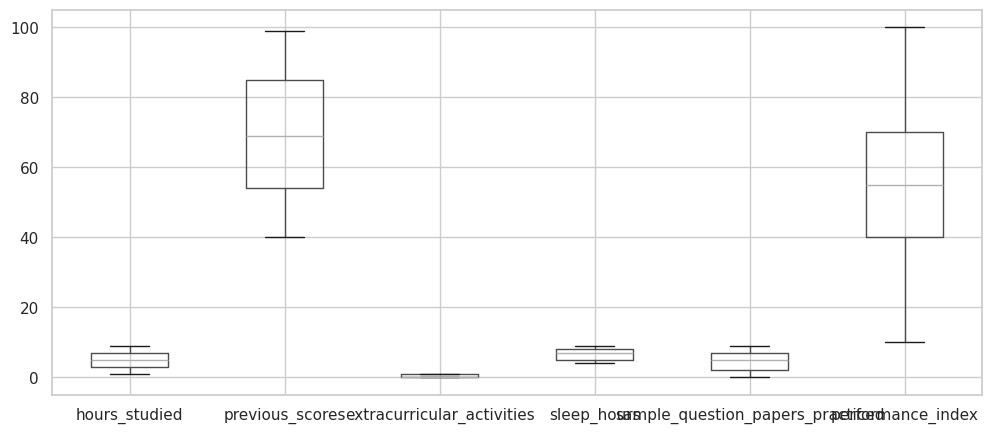

In [11]:
target = "performance_index"

# 5a. Distribution of each variable
df.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

# 5b. Correlation with the target
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()
print(df.corr()[target].sort_values(ascending=False))

# 5c. Relationship of key predictors with the target
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=df, x="previous_scores", y=target, alpha=0.3, ax=axes[0])
sns.scatterplot(data=df, x="hours_studied", y=target, alpha=0.3, ax=axes[1])
sns.boxplot(data=df, x="extracurricular_activities", y=target, ax=axes[2])
plt.tight_layout()
plt.show()

# 5d. Outliers
df.boxplot(figsize=(12, 5))
plt.show()

In [13]:
X = df.drop(columns=[target])
y = df[target]
print(y)

0       91.0
1       65.0
2       45.0
3       36.0
4       66.0
        ... 
9868    23.0
9869    58.0
9870    74.0
9871    95.0
9872    64.0
Name: performance_index, Length: 9873, dtype: float64


In [15]:
# Optional: interaction feature (does studying matter more for students with strong past scores?)
X["study_x_prev"] = X["hours_studied"] * X["previous_scores"]

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [17]:
num_cols = X.columns.drop("extracurricular_activities")

preprocess = ColumnTransformer(
    [("scale", StandardScaler(), num_cols)],
    remainder="passthrough"   # leaves the 0/1 column untouched
)

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}

results = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2").mean()

    results.append({
        "Model": name,
        "R2 (test)": r2_score(y_test, pred),
        "R2 (5-fold CV)": cv_r2,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    })

pd.DataFrame(results).sort_values("R2 (test)", ascending=False)

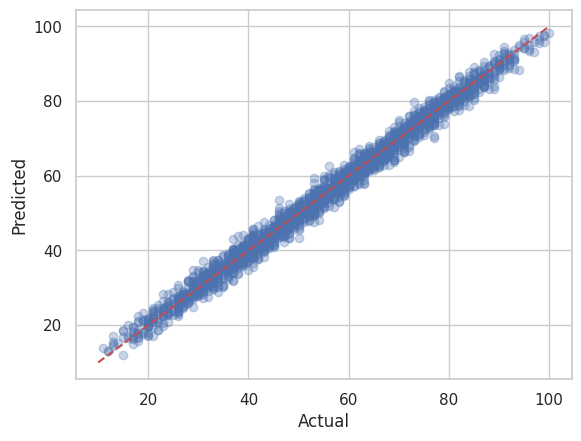

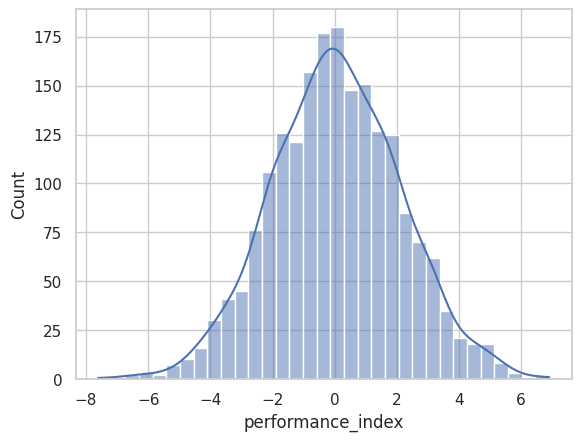

previous_scores                     17.618652
hours_studied                        7.370674
sleep_hours                          0.802147
extracurricular_activities           0.573811
sample_question_papers_practiced     0.540050
study_x_prev                         0.002999
dtype: float64


In [18]:
best = Pipeline([("prep", preprocess), ("model", LinearRegression())])
best.fit(X_train, y_train)
pred = best.predict(X_test)

# Actual vs predicted
plt.scatter(y_test, pred, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.show()

# Residuals (should look like random noise centered on 0)
residuals = y_test - pred
sns.histplot(residuals, kde=True)
plt.show()

# Which features matter most?
coefs = pd.Series(best.named_steps["model"].coef_,
                  index=list(num_cols) + ["extracurricular_activities"])
print(coefs.sort_values(ascending=False))

In [21]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [22]:
alphas = np.logspace(-4, 2, 50)

models = {
    "Linear":  make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge":   make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=5)),
    "Lasso":   make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=5, max_iter=10000, random_state=42)),
}

for m in models.values():
    m.fit(X_train, y_train)

print("Ridge alpha:", models["Ridge"][-1].alpha_)
print("Lasso alpha:", models["Lasso"][-1].alpha_)

Ridge alpha: 0.1151395399326447
Lasso alpha: 0.0016768329368110084


In [23]:
rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R² (test)": r2_score(y_test, pred),
        "R² (train)": r2_score(y_train, m.predict(X_train)),
    })

comparison = pd.DataFrame(rows).set_index("Model").round(4)
comparison["Train-Test gap"] = (comparison["R² (train)"] - comparison["R² (test)"]).round(4)
display(comparison)

,MAE,MSE,RMSE,R² (test),R² (train),Train-Test gap
Model,,,,,,
Linear,1.6470,4.3059,2.0751,0.9884,0.9887,0.0003
Ridge,1.6470,4.3060,2.0751,0.9884,0.9887,0.0003
Lasso,1.6472,4.3071,2.0754,0.9884,0.9887,0.0003


,Linear,Ridge,Lasso
hours_studied,7.3707,7.3669,7.3549
previous_scores,17.6187,17.6166,17.6101
extracurricular_activities,0.2869,0.2869,0.2852
sleep_hours,0.8021,0.8021,0.8005
sample_question_papers_practiced,0.5400,0.5400,0.5384
study_x_prev,0.0030,0.0072,0.0188


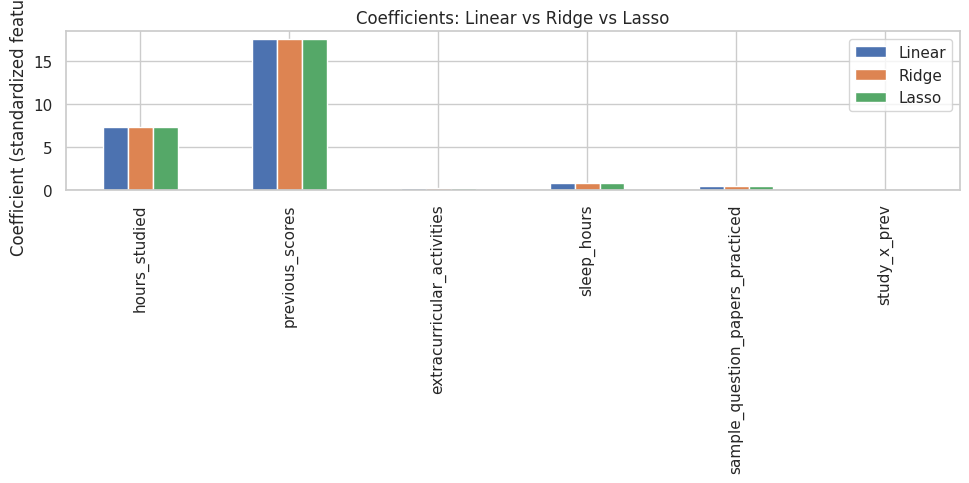

In [24]:
coef_df = pd.DataFrame({
    name: m[-1].coef_ for name, m in models.items()
}, index=X.columns).round(4)
display(coef_df)

coef_df.plot(kind="bar", figsize=(10, 5), title="Coefficients: Linear vs Ridge vs Lasso")
plt.axhline(0, color="black", lw=0.8)
plt.ylabel("Coefficient (standardized features)")
plt.tight_layout(); plt.show()

All three models generalize equally well (test R² = 0.9884, RMSE ≈ 2.075, train-test gap = 0.0003), with Linear Regression marginally ahead, so no model shows overfitting. Regularization had almost no effect on accuracy because the dataset is large and low-dimensional with weakly correlated predictors; it only shrank the coefficients slightly. I recommend Linear Regression as the simplest model that performs just as well.